# 02 · The products against public reference data (tier 2)

How accurate are the products *in Guinea*, judged against reference data that people interpreted from imagery and that are already public?

Notebook 01 found that no published accuracy is for Guinea. Guinea's own reference plots (NERF, 1,688 plots) are not public. So this notebook uses what is public and covers Guinea.

| Dataset | What it is | In Guinea | Used here |
|---|---|---|---|
| **GLanCE training data** (Stanimirova et al. 2023) | Points labelled by interpreters on Landsat and high-resolution imagery, with the period each label holds; 7 classes | 565 points, mostly labels for 2018 | **Yes**: class at a point, for the land-cover maps and the forest maps |
| **Geo-Wiki crowdsourced data** (Fritz et al. 2017) | Volunteers estimated the share of each cover type in areas of about 1 km (a 1/120° grid), on Google Earth images of 2004–2012 | 177 areas, 341 ratings | **Yes**: share of tree cover, to test the forest maps and the canopy threshold |
| Dynamic World expert tiles (Brown et al. 2022) | 10 m tiles labelled by experts | none in Guinea (5 in neighbouring countries) | No. Also used to train Esri's model, so not independent of it (Xu et al. 2024) |
| FAO FRA 2020 remote sensing survey; WorldCover and JRC validation points; NERF plots | Probability samples | – | No public download found |

These points were collected for other purposes and are not a probability sample of Guinea: they cannot give unbiased map accuracies or areas (Olofsson et al. 2014; Stehman & Foody 2019). They can show, on a few hundred independent places, whether the products agree with what interpreters saw, and which product and which forest definition agree best. Only 8 of the 565 GLanCE points record a change, so **this tier tests maps of one date, not change**: change needs tier 3.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parents[1]                                          # .../Guinea_Methodology
STUDIES = ROOT / "studies"
OUT = Path.cwd() / "output"
OUT.mkdir(exist_ok=True)
REF = Path.cwd() / "reference_data"                                   # downloaded public datasets
FORCE_RESAMPLE = False                                                # True = read Earth Engine again

guinea = gpd.read_file(STUDIES / "output_datasets" / "ecoregions_guinea.gpkg", layer="guinea_boundary").to_crs(4326)

COMMON = {1: "Tree cover", 2: "Shrub & grassland", 3: "Cropland", 4: "Built-up", 5: "Bare", 6: "Water", 7: "Herbaceous wetland"}
# The products' own codes to the common legend, and what counts as forest: as in ../lulc_benchmark.ipynb (section 3)
PRODUCTS = {
    "esri": {"label": "Esri", "crosswalk": {1: 6, 2: 1, 4: 7, 5: 3, 7: 4, 8: 5, 11: 2}, "forest": [2]},
    "dynamic_world": {"label": "Dynamic World", "crosswalk": {0: 6, 1: 1, 2: 2, 3: 7, 4: 3, 5: 2, 6: 4, 7: 5}, "forest": [1]},
    "worldcover": {"label": "WorldCover", "crosswalk": {10: 1, 20: 2, 30: 2, 40: 3, 50: 4, 60: 5, 80: 6, 90: 7, 95: 1, 100: 2},
                   "forest": [10, 95]},
    "glc_fcs30d": {"label": "GLC_FCS30D", "forest": [51, 52, 61, 62, 71, 72, 81, 82, 91, 92, 185],
                   "crosswalk": {10: 3, 11: 3, 12: 3, 20: 3, 51: 1, 52: 1, 61: 1, 62: 1, 71: 1, 72: 1, 81: 1, 82: 1, 91: 1,
                                 92: 1, 120: 2, 121: 2, 122: 2, 130: 2, 140: 2, 150: 5, 152: 5, 153: 5, 181: 7, 182: 7,
                                 183: 7, 184: 7, 185: 1, 186: 7, 187: 7, 190: 4, 200: 5, 201: 5, 202: 5, 210: 6}},
    "tmf": {"label": "JRC TMF", "forest": [1, 2, 4]},
    "gfc2020": {"label": "JRC GFC2020", "forest": [1]},
}

## 1 · Reading the reference data and the products

Earth Engine is used once, with the project's service account as in `../lulc_benchmark.ipynb`; the
values are saved in `output/`, so reruns cost nothing.

In [2]:
def earth_engine():
    import ee
    key = next(p for p in [ROOT / "gee-account.json", *(ROOT / "Land Use-Deforestation" / "landuse_tool" / "credentials").glob("tribal*.json")]
               if p.exists())
    info = json.loads(key.read_text())
    ee.Initialize(ee.ServiceAccountCredentials(info["client_email"], str(key)), project=info["project_id"])
    return ee


GLANCE = OUT / "02_glance_points.parquet"
if GLANCE.exists() and not FORCE_RESAMPLE:
    glance = pd.read_parquet(GLANCE)
else:
    ee = earth_engine()
    region = ee.Geometry(guinea.geometry.iloc[0].__geo_interface__)
    fc = ee.FeatureCollection("projects/sat-io/open-datasets/GLANCE/GLANCE_TRAINING_DATA_V1").filterBounds(region)
    glance = pd.DataFrame([f["properties"] for f in fc.getInfo()["features"]])
    glance.to_parquet(GLANCE, index=False)
print(f"GLanCE points in Guinea: {len(glance)}")


def common_class(row):
    """GLanCE level 1 (and level 2, modifiers) to the common legend. Herbaceous is split by its level-2 class
    and modifiers: agriculture or cropland -> cropland, wetland -> herbaceous wetland, otherwise grassland."""
    l1, l2, modifier = row["Glance_Class_ID_level1"], row.get("Glance_Class_ID_level2"), str(row.get("Veg_Modifier"))
    if l1 == 7:
        if l2 == 12 or "Cropland" in modifier:
            return 3
        return 7 if "Wetland" in modifier else 2
    return {1: 6, 3: 4, 4: 5, 5: 1, 6: 2}.get(l1, 0)


glance["reference"] = glance.apply(common_class, axis=1)
glance["pid"] = np.arange(len(glance))                     # Glance_ID is too long for Earth Engine integers
glance["year"] = glance["End_Year"].clip(upper=2020)        # the label holds from Start_Year to End_Year
pd.crosstab(glance["reference"].map(COMMON), glance["year"], margins=True)

GLanCE points in Guinea: 565


year,2004,2005,2006,2007,2008,2009,2012,2013,2014,2015,2017,2018,2020,All
reference,,,,,,,,,,,,,,
Bare,0,0,0,0,0,0,0,0,0,0,0,1,0,1
Built-up,0,1,0,0,0,0,0,0,0,29,0,40,0,70
Cropland,0,0,0,1,1,0,1,0,0,0,0,63,0,66
Herbaceous wetland,0,0,0,0,0,0,0,0,0,0,0,0,3,3
Shrub & grassland,0,0,2,0,0,0,0,1,3,2,1,135,0,144
Tree cover,1,0,1,1,1,1,2,0,2,10,0,250,1,270
Water,0,0,0,0,0,0,0,0,0,2,0,7,2,11
All,1,1,3,2,2,1,3,1,5,43,1,496,6,565


Where the points are. Most GLanCE points are in the West Sudanian savanna (364 of 565); few are in the lowland
and montane forests, where much of the forest loss is.

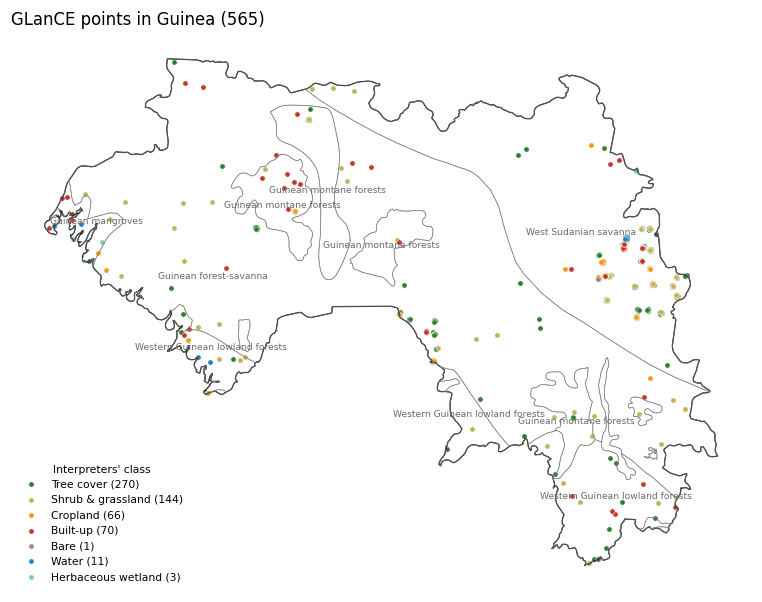

In [3]:
ECOREGIONS = gpd.read_file(STUDIES / "output_datasets" / "ecoregions_guinea.gpkg", layer="ecoregions_guinea").to_crs(4326)
CLASS_COLORS = {"Tree cover": "#2e7d32", "Shrub & grassland": "#c5b358", "Cropland": "#f39c12", "Built-up": "#c0392b",
                "Bare": "#a1887f", "Water": "#2980b9", "Herbaceous wetland": "#7fcdbb"}   # as in ../lulc_benchmark.ipynb


def base_map(ax):
    """Guinea and its ecoregions, with one name inside each part larger than 2,000 km²."""
    guinea.boundary.plot(ax=ax, color="black", linewidth=0.8)
    ECOREGIONS.boundary.plot(ax=ax, color="grey", linewidth=0.4)
    parts = ECOREGIONS.explode(index_parts=False)
    parts = parts[parts.to_crs(parts.estimate_utm_crs()).area > 2e9]
    for name, point in zip(parts["ECO_NAME"], parts.representative_point()):
        ax.annotate(name, (point.x, point.y), fontsize=6, color="dimgrey", ha="center")
    ax.set_axis_off()


glance_points = gpd.GeoDataFrame(glance, geometry=gpd.points_from_xy(glance.Lon, glance.Lat), crs=4326)
fig, ax = plt.subplots(figsize=(7, 6))
base_map(ax)
for name, color in CLASS_COLORS.items():
    subset = glance_points[glance_points["reference"].map(COMMON) == name]
    if len(subset):
        subset.plot(ax=ax, color=color, markersize=12, edgecolor="white", linewidth=0.3, label=f"{name} ({len(subset)})")
ax.legend(loc="lower left", fontsize=7, frameon=False, title="Interpreters' class", title_fontsize=7)
ax.set_title(f"GLanCE points in Guinea ({len(glance_points)})", loc="left")
plt.tight_layout(); plt.show()


In [4]:
def build_image(ee, key):
    """One band per year named "2017", ... with the product's own codes (Hansen: its three bands)."""
    bbox = ee.Geometry.Rectangle(list(guinea.total_bounds))
    if key == "esri":
        col = ee.ImageCollection("projects/sat-io/open-datasets/landcover/ESRI_Global-LULC_10m_TS").filterBounds(bbox)
        return ee.Image.cat([col.filterDate(f"{y}-01-01", f"{y + 1}-01-01").mosaic().select([0], [str(y)]) for y in range(2017, 2021)])
    if key == "dynamic_world":                          # most frequent label of 2018, the year of most GLanCE labels
        col = ee.ImageCollection("GOOGLE/DYNAMICWORLD/V1").filterBounds(bbox).select("label")
        return col.filterDate("2018-01-01", "2019-01-01").mode().rename("2018")
    if key == "worldcover":
        return ee.ImageCollection("ESA/WorldCover/v100").first().select([0], ["2020"])
    if key == "glc_fcs30d":                             # b1 = 2000, b2 = 2001, ...
        img = ee.ImageCollection("projects/sat-io/open-datasets/GLC-FCS30D/annual").mosaic()
        return img.select([f"b{y - 1999}" for y in range(2000, 2021)], [str(y) for y in range(2000, 2021)])
    if key == "tmf":
        img = ee.ImageCollection("projects/JRC/TMF/v1_2025/AnnualChanges").mosaic()
        return img.select([f"Dec{y}" for y in range(2000, 2021)], [str(y) for y in range(2000, 2021)]).unmask(6)
    if key == "gfc2020":
        return ee.Image("JRC/GFC2020/V3").select([0], ["2020"]).unmask(0)
    if key == "hansen":
        h = ee.Image("UMD/hansen/global_forest_change_2025_v1_13")
        return h.select(["treecover2000", "datamask"]).addBands(h.select("lossyear").unmask(0))


SCALE = {"esri": 10, "dynamic_world": 10, "worldcover": 10, "gfc2020": 10, "glc_fcs30d": 30, "tmf": 30, "hansen": 30}
VALUES = OUT / "02_glance_products.parquet"
if VALUES.exists() and not FORCE_RESAMPLE:
    values = pd.read_parquet(VALUES)
else:
    ee = earth_engine()
    pts = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([lon, lat]), {"pid": int(i)})
                                for i, lon, lat in zip(glance["pid"], glance["Lon"], glance["Lat"])])
    frames = []
    for key, scale in SCALE.items():
        rows = build_image(ee, key).unmask(-1).sampleRegions(collection=pts, properties=["pid"], scale=scale).getInfo()
        frame = pd.DataFrame([f["properties"] for f in rows["features"]]).set_index("pid")
        frames.append(frame.add_prefix(f"{key}_"))
        print(f"{key}: {len(frame)} points")
    values = pd.concat(frames, axis=1).reset_index()
    values.to_parquet(VALUES, index=False)
data = glance.merge(values, on="pid")

## 2 · Land cover at the GLanCE points

For each point, the product's class in the year the GLanCE label holds (Esri and Dynamic World:
labels valid in 2017–2020 and 2018; WorldCover, 2020 only, compared with labels of 2018–2020).
Agreement is the share of points where the product's class matches the interpreter's, with a 95 %
confidence interval (Wilson). The six classes with few points (water, bare, wetland) are kept in
the overall figure but are too few to judge on their own.

In [5]:
def wilson(k, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = k / n
    centre, half = (p + z**2 / (2 * n)) / (1 + z**2 / n), z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return 100 * (centre - half), 100 * (centre + half)


def product_value(key, row):
    """The product's code at the point in the label's year, or None if the product has no map for it."""
    year = {"dynamic_world": 2018, "worldcover": 2020, "gfc2020": 2020}.get(key, row["year"])
    if key == "dynamic_world" and not row["Start_Year"] <= 2018 <= row["End_Year"]:
        return None
    if key == "worldcover" and row["End_Year"] < 2018:
        return None
    value = row.get(f"{key}_{year}")
    return None if value is None or pd.isna(value) or value < 0 else int(value)


rows, confusion = [], {}
for key in ("esri", "dynamic_world", "worldcover", "glc_fcs30d"):
    spec = PRODUCTS[key]
    pairs = [(r["reference"], spec["crosswalk"].get(product_value(key, r), 0)) for _, r in data.iterrows()
             if product_value(key, r) is not None and r["reference"] > 0]
    ref, prod = (np.array(x) for x in zip(*pairs))
    low, high = wilson((ref == prod).sum(), len(ref))
    rows.append({"Product": spec["label"], "Points": len(ref), "Agreement %": 100 * (ref == prod).mean(),
                 "95 % CI": f"{low:.0f}–{high:.0f}"})
    confusion[spec["label"]] = pd.crosstab(pd.Series(ref).map(COMMON).rename("GLanCE"), pd.Series(prod).map(COMMON).rename(spec["label"]))
land_cover = pd.DataFrame(rows).set_index("Product")
land_cover.round(1).to_csv(OUT / "02_land_cover_agreement.csv")
land_cover.round(1)

,Points,Agreement %,95 % CI
Product,,,
Esri,503,75.1,71–79
Dynamic World,502,77.1,73–81
WorldCover,502,86.3,83–89
GLC_FCS30D,565,63.4,59–67


In [6]:
print("Esri against GLanCE (points); rows = interpreter, columns = Esri")
confusion["Esri"]

Esri against GLanCE (points); rows = interpreter, columns = Esri


Esri,Built-up,Cropland,Herbaceous wetland,Shrub & grassland,Tree cover,Water
GLanCE,,,,,,
Bare,0,0,0,1,0,0
Built-up,40,0,0,0,0,0
Cropland,10,15,1,24,13,0
Herbaceous wetland,0,0,0,3,0,0
Shrub & grassland,8,1,0,87,40,0
Tree cover,1,0,1,21,227,1
Water,0,0,0,0,0,9


**Reading:**

* **WorldCover agrees best with the interpreters (86 %), then Dynamic World (77 %) and Esri
  (75 %); GLC_FCS30D least (63 %).** The ranking of the three 10 m maps is the same as in the global
  independent validation (Xu et al. 2024; notebook 01).
* **Esri's errors are between trees, grassland and cropland:** of the points interpreters called
  shrub & grassland, Esri calls 40 of 136 tree cover; of those they called cropland, Esri calls
  only 15 of 63 cropland. These are the classes between which Esri changes most from year to year
  (notebook 01, section 4).

## 3 · Forest at the GLanCE points

GLanCE's *trees* class against each product's forest, in the label's year. Producer's accuracy: of
the points the interpreters called trees, the share the product calls forest. User's accuracy: of
the points the product calls forest, the share the interpreters called trees (Olofsson et al. 2014).
Hansen is shown at three canopy thresholds; forest = canopy above the threshold in 2000 and no loss
by the label's year.

In [7]:
def forest_flag(key, row):
    if key.startswith("hansen"):
        threshold = int(key.split("_")[1])
        lost = 0 < row["hansen_lossyear"] <= row["year"] - 2000
        return (row["hansen_treecover2000"] > threshold) and not lost
    value = product_value(key, row)
    return None if value is None else value in PRODUCTS[key]["forest"]


rows = []
for key, label in [("hansen_10", "Hansen, canopy > 10 %"), ("hansen_30", "Hansen, canopy > 30 %"), ("hansen_50", "Hansen, canopy > 50 %"),
                   ("tmf", "JRC TMF"), ("gfc2020", "JRC GFC2020"), ("esri", "Esri"), ("dynamic_world", "Dynamic World"),
                   ("worldcover", "WorldCover"), ("glc_fcs30d", "GLC_FCS30D")]:
    pairs = [(r["reference"] == 1, forest_flag(key, r)) for _, r in data.iterrows()
             if r["reference"] > 0 and forest_flag(key, r) is not None and not (key == "gfc2020" and r["End_Year"] < 2018)]
    ref, prod = (np.array(x, bool) for x in zip(*pairs))
    pa_low, pa_high = wilson((ref & prod).sum(), ref.sum())
    ua_low, ua_high = wilson((ref & prod).sum(), prod.sum())
    rows.append({"Product": label, "Points": len(ref), "Trees (GLanCE)": int(ref.sum()), "Forest (product)": int(prod.sum()),
                 "Producer's accuracy %": 100 * (ref & prod).sum() / max(ref.sum(), 1), "PA 95 % CI": f"{pa_low:.0f}–{pa_high:.0f}",
                 "User's accuracy %": 100 * (ref & prod).sum() / max(prod.sum(), 1), "UA 95 % CI": f"{ua_low:.0f}–{ua_high:.0f}"})
forest = pd.DataFrame(rows).set_index("Product")
forest.round(1).to_csv(OUT / "02_forest_accuracy.csv")
trees = data[data["reference"] == 1]
print(f"Hansen canopy in 2000 where the interpreters saw trees: median {trees.hansen_treecover2000.median():.0f} %, "
      f"middle half {trees.hansen_treecover2000.quantile(0.25):.0f}–{trees.hansen_treecover2000.quantile(0.75):.0f} %")
forest.round(1)

Hansen canopy in 2000 where the interpreters saw trees: median 28 %, middle half 20–44 %


,Points,Trees (GLanCE),Forest (product),Producer's accuracy %,PA 95 % CI,User's accuracy %,UA 95 % CI
Product,,,,,,,
"Hansen, canopy > 10 %",565,270,462,97.8,95–99,57.1,53–62
"Hansen, canopy > 30 %",565,270,131,40.7,35–47,84.0,77–89
"Hansen, canopy > 50 %",565,270,22,7.8,5–12,95.5,78–99
JRC TMF,565,270,8,3.0,2–6,100.0,68–100
JRC GFC2020,502,251,240,76.9,71–82,80.4,75–85
Esri,503,251,280,90.4,86–93,81.1,76–85
Dynamic World,502,251,298,96.8,94–98,81.5,77–86
WorldCover,502,251,244,92.8,89–95,95.5,92–97
GLC_FCS30D,565,270,428,99.3,97–100,62.6,58–67


**Reading:**

* **What the interpreters call trees is open woodland as much as dense forest:** Hansen's canopy at
  their tree points has a median of 28 %. So Hansen at the legal 10 % threshold finds almost all of
  them (producer's accuracy 98 %) but calls forest many places they did not see as trees (user's
  accuracy 57 %); at 30 % it is the reverse (41 % and 84 %). Neither threshold matches; the forest
  definition decides the result more than the product does, as stage 1 found.
* **WorldCover has the best balance** (93 % and 96 %), then Dynamic World and Esri (both about
  81 % user's accuracy). GLC_FCS30D calls forest too widely (user's accuracy 63 %).
* **JRC TMF finds only 8 of 270 tree points:** it maps moist forest only, which is a small part of
  Guinea (notebook 01).
* The points are few and not a random sample of Guinea, so these are indications, not the map
  accuracies tier 3 will estimate.

## 4 · Tree cover in the Geo-Wiki areas

Volunteers estimated the share of each ~1 km area covered by trees on Google Earth images, mostly of
2004–2012. Each area is compared with the share of its Hansen pixels above each canopy threshold in
2010 (no loss in 2001–2010) and the share of GLC_FCS30D forest in 2010. The threshold whose share
matches the volunteers' tree cover best is the one closest to what people see as trees.

In [8]:
gw = pd.read_csv(REF / "geowiki_fritz2017" / "global_lulc_reference_data.csv")
gw = gpd.GeoDataFrame(gw, geometry=gpd.points_from_xy(gw.lon, gw.lat), crs=4326)
gw = gw[gw.within(guinea.geometry.iloc[0])].copy()
gw["tree_%"] = sum(np.where(gw[f"LC{i}"] == 1, gw[f"perc{i}"], 0) for i in (1, 2, 3))
print(f"Ratings made with high-resolution imagery: {int(gw.highres.sum())} of {len(gw)}")
cells = gw.groupby("pixelID").agg(lon=("lon", "first"), lat=("lat", "first"), tree=("tree_%", "mean"),
                                  ratings=("userID", "size")).reset_index()
print(f"Geo-Wiki in Guinea: {len(gw)} ratings of {len(cells)} areas; image years "
      f"{pd.to_datetime(gw['googleimagedate'], errors='coerce').dt.year.describe()[['min', '50%', 'max']].astype('Int64').tolist()} (min, median, max)")

CELLS = OUT / "02_geowiki_cells.parquet"
if CELLS.exists() and not FORCE_RESAMPLE:
    cells = pd.read_parquet(CELLS)
else:
    ee = earth_engine()
    half = 1 / 240                                       # the 1/120° grid cell around each centre
    boxes = ee.FeatureCollection([ee.Feature(ee.Geometry.Rectangle([x - half, y - half, x + half, y + half]), {"pixelID": int(i)})
                                  for i, x, y in zip(cells.pixelID, cells.lon, cells.lat)])
    h = ee.Image("UMD/hansen/global_forest_change_2025_v1_13")
    kept = h.select("lossyear").unmask(0).Not().Or(h.select("lossyear").gt(10))          # no loss in 2001-2010
    glc = ee.ImageCollection("projects/sat-io/open-datasets/GLC-FCS30D/annual").mosaic().select("b11")   # 2010
    shares = ee.Image.cat([h.select("treecover2000").gt(t).And(kept).rename(f"hansen_{t}") for t in (10, 30, 50)]
                          + [glc.remap(PRODUCTS["glc_fcs30d"]["forest"], [1] * 11, 0).rename("glc_fcs30d")])
    out = shares.reduceRegions(collection=boxes, reducer=ee.Reducer.mean(), scale=30).getInfo()
    cells = cells.merge(pd.DataFrame([f["properties"] for f in out["features"]]), on="pixelID")
    cells.to_parquet(CELLS, index=False)

rows = []
for col, label in [("hansen_10", "Hansen, canopy > 10 %"), ("hansen_30", "Hansen, canopy > 30 %"),
                   ("hansen_50", "Hansen, canopy > 50 %"), ("glc_fcs30d", "GLC_FCS30D forest")]:
    ok = cells[col].notna()                              # a few areas on the border have no Hansen value
    product, volunteers = 100 * cells.loc[ok, col], cells.loc[ok, "tree"]
    rows.append({"Map, 2010": label, "Areas": int(ok.sum()), "Mean share of the area (%)": product.mean(),
                 "Volunteers' tree cover (%)": volunteers.mean(),
                 "Mean difference (points)": (product - volunteers).mean(),
                 "Mean absolute difference (points)": (product - volunteers).abs().mean(),
                 "Correlation": product.corr(volunteers)})
tree_share = pd.DataFrame(rows).set_index("Map, 2010")
tree_share.round(2).to_csv(OUT / "02_geowiki_tree_cover.csv")
tree_share.round(2)

Ratings made with high-resolution imagery: 10 of 341
Geo-Wiki in Guinea: 341 ratings of 177 areas; image years [2001, 2009, 2012] (min, median, max)


,Areas,Mean share of the area (%),Volunteers' tree cover (%),Mean difference (points),Mean absolute difference (points),Correlation
"Map, 2010",,,,,,
"Hansen, canopy > 10 %",158,75.78,35.54,40.24,53.07,0.11
"Hansen, canopy > 30 %",158,33.97,35.54,-1.57,38.03,0.14
"Hansen, canopy > 50 %",158,9.20,35.54,-26.34,36.41,0.03
GLC_FCS30D forest,177,87.58,34.31,53.27,56.08,0.25


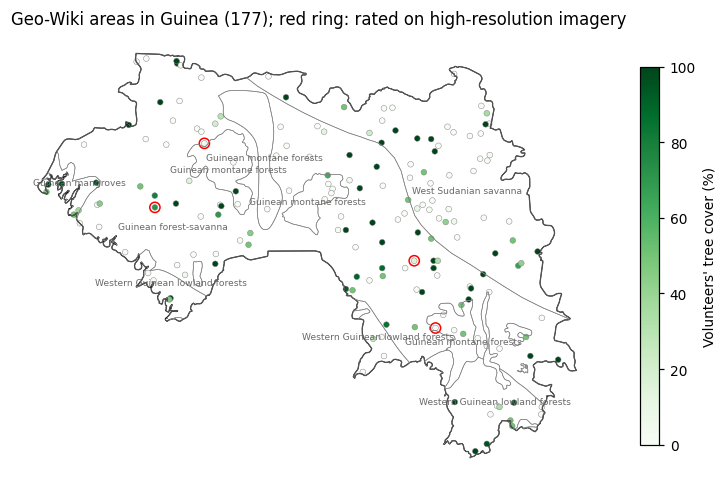

In [9]:
geowiki_areas = gpd.GeoDataFrame(cells, geometry=gpd.points_from_xy(cells.lon, cells.lat), crs=4326)
geowiki_areas["high_res"] = geowiki_areas["pixelID"].map(gw.groupby("pixelID")["highres"].max()).fillna(0).astype(bool)
fig, ax = plt.subplots(figsize=(7, 6))
base_map(ax)
geowiki_areas.plot(ax=ax, column="tree", cmap="Greens", vmin=0, vmax=100, markersize=14, edgecolor="grey", linewidth=0.3,
                   legend=True, legend_kwds={"label": "Volunteers' tree cover (%)", "shrink": 0.6})
geowiki_areas[geowiki_areas["high_res"]].plot(ax=ax, facecolor="none", edgecolor="red", markersize=45, linewidth=1)
ax.set_title(f"Geo-Wiki areas in Guinea ({len(geowiki_areas)}); red ring: rated on high-resolution imagery", loc="left")
plt.tight_layout(); plt.show()


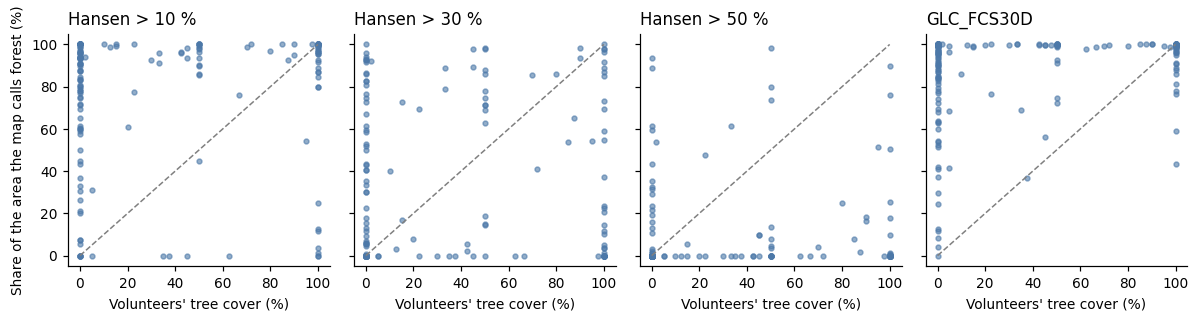

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=True)
for ax, (col, label) in zip(axes, [("hansen_10", "Hansen > 10 %"), ("hansen_30", "Hansen > 30 %"),
                                   ("hansen_50", "Hansen > 50 %"), ("glc_fcs30d", "GLC_FCS30D")]):
    ax.scatter(cells["tree"], 100 * cells[col], s=10, alpha=0.6, color="#4c78a8")
    ax.plot([0, 100], [0, 100], color="grey", linewidth=1, linestyle="--")
    ax.set_title(label, loc="left")
    ax.set_xlabel("Volunteers' tree cover (%)")
axes[0].set_ylabel("Share of the area the map calls forest (%)")
plt.tight_layout(); plt.show()

**Reading:**

* **Area by area, the volunteers' tree cover and the maps hardly agree** (correlations 0.03–0.25,
  mean absolute differences of 36–56 points). The cause is the reference data: **331 of the 341
  ratings in Guinea were made without high-resolution imagery**, so the volunteers judged tree cover
  from coarse images.
* On average, the share above Hansen's 30 % canopy (34 %) is close to the volunteers' tree cover
  (36 %), and the 10 % threshold far above it (76 %). Given the quality of the ratings, this is a
  weak indication only. **Geo-Wiki is not good enough in Guinea to judge the forest maps.**

## 5 · What tier 2 shows, and what is left for tier 3

* **For land cover, WorldCover and Dynamic World agree with interpreters better than Esri**, in Guinea
  as globally. Esri, which the land-use forecast uses, is the least accurate of the three 10 m maps
  and the least stable from year to year (notebook 01).
* **For forest, the definition matters more than the product.** Where GLanCE's interpreters saw
  trees, Hansen's canopy has a median of 28 %: the 10 % threshold calls too much forest, the 30 %
  threshold misses more than half of their trees. The operational definition has to be decided
  first (stage 1, decision 1); tier 3 should record canopy cover, not only forest / non-forest, so
  that any threshold can be scored.
* **Geo-Wiki is not usable in Guinea:** almost all its ratings were made without high-resolution
  imagery.
* **Change could not be tested:** the public data hold 8 changed points in Guinea. The accuracy of
  forest loss and of land-cover change, the quantities the platform reports, needs our own sample
  (tier 3), stratified where the products disagree and where change happens.

### References

* Brown, C.F., Brumby, S.P., Guzder-Williams, B., et al. (2022). Dynamic World, near real-time global 10 m land
  use land cover mapping. *Scientific Data* 9, 251.
* Fritz, S., See, L., Perger, C., et al. (2017). A global dataset of crowdsourced land cover and land use reference
  data. *Scientific Data* 4, 170075.
* Olofsson, P., Foody, G.M., Herold, M., et al. (2014). Good practices for estimating area and assessing accuracy of
  land change. *Remote Sensing of Environment* 148, 42–57.
* Stanimirova, R., Tarrio, K., Turlej, K., et al. (2023). A global land cover training dataset from 1984 to 2020.
  *Scientific Data* 10, 879.
* Stehman, S.V., Foody, G.M. (2019). Key issues in rigorous accuracy assessment of land cover products. *Remote
  Sensing of Environment* 231, 111199.
* Xu, P., Tsendbazar, N.-E., Herold, M., et al. (2024). Comparative validation of recent 10 m-resolution global land
  cover maps. *Remote Sensing of Environment* 311, 114316.